# SMT em Tempo
## Previsão da duração da troca de produto na linha SMT

**Projeto 4 - Trabalho final de Machine Learning**

**Equipe:** Juliana Ballin Lima, Fernanda de Oliveira da Costa e Pedro Henrique Oliveira Dias

Este notebook investiga quais trocas precisam de atenção antes de começar. A análise responde duas perguntas:

1. Quantos minutos a troca deve levar?
2. A troca deve ultrapassar 42 minutos?

Os dados são sintéticos e foram preparados para o curso.

## 1. Como a análise foi organizada

Seguimos o ciclo usado nas aulas:

**observar → decidir → corrigir → conferir → dividir no tempo → treinar → avaliar**

O conjunto de teste fica reservado até o final. Assim, ele simula trocas futuras que o modelo ainda não viu.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

from fontes.analise import (
    CATEGORICAL_FEATURES,
    FEATURES,
    NUMERIC_FEATURES,
    clean_data,
    generate_charts,
    read_raw_data,
    save_outputs,
    temporal_split,
    train_and_evaluate,
)

pd.set_option("display.max_columns", 30)
pd.set_option("display.precision", 3)
PROJECT_DIR = Path.cwd()
print("Pasta do projeto:", PROJECT_DIR)

Pasta do projeto: /home/cronos-1226/Documentos/SiaLabs/cursos-denken/machine-learning/projeto-final/SMT-Changeover-Prediction


## 2. Abrir e compreender o dataset

Cada linha representa uma troca de produto. As oito entradas abaixo existem antes da troca e podem apoiar a previsão.

| Entrada | Significado |
|---|---|
| `alimentadores_a_trocar` | carretéis que precisam ser substituídos |
| `kit_preparado_pct` | percentual do kit já separado |
| `experiencia_operador_meses` | experiência do operador |
| `componentes_novos` | componentes ainda não usados pela linha |
| `tamanho_lote_placas` | placas previstas no lote seguinte |
| `linha_smt` | linha SMT1, SMT2 ou SMT3 |
| `muda_familia` | indica mudança de família de produto |
| `turno` | manhã, tarde ou noite |

`tempo_troca_min` é o alvo da regressão. `troca_demorada` é o alvo da classificação. `atraso_no_plano_min` só existe depois do fato e não entra nos modelos.

In [2]:
bruto = read_raw_data()
print("Dimensão recebida:", bruto.shape)
display(bruto.head(6))

Dimensão recebida: (2057, 14)


,id_registro,instante_previsao,data_operacao,linha_smt,muda_familia,turno,alimentadores_a_trocar,kit_preparado_pct,experiencia_operador_meses,componentes_novos,tamanho_lote_placas,tempo_troca_min,troca_demorada,atraso_no_plano_min
0,N4-000001,2026-01-05T08:15:00,2026-01-05,SMT2,Não,Manhã,33.0,28.0,70.0,3.0,1000.0,33.8,0,0.0
1,N4-000002,2026-01-05T08:15:00,2026-01-05,SMT1,Sim,Manhã,20.0,86.0,14.0,2.0,2000.0,30.9,0,0.0
2,N4-000003,2026-01-05T10:15:00,2026-01-05,SMT1,Não,Manhã,44.0,19.0,60.0,7.0,50.0,47.8,1,13.0
3,N4-000004,2026-01-05T17:45:00,2026-01-05,SMT3,Sim,Tarde,11.0,79.0,32.0,4.0,50.0,26.6,0,0.0
4,N4-000005,2026-01-05T19:45:00,2026-01-05,SMT1,Não,Tarde,13.0,8.0,78.0,1.0,1000.0,25.5,0,0.0
5,N4-000006,2026-01-05T21:15:00,2026-01-05,SMT3,Sim,Tarde,48.0,83.0,22.0,1.0,250.0,41.4,0,7.0


## 3. Limpeza rastreável

A base contém cópias exatas, espaços escondidos, grafias diferentes, vazios, vírgulas decimais, códigos `9999`, datas em dois formatos e medidas fora dos critérios didáticos.

Somente duplicatas exatas são removidas. Medidas inválidas viram ausentes no campo afetado, sem apagar a troca inteira. Os alvos não são preenchidos.

In [3]:
dados, registro_limpeza, suspeitas, qualidade = clean_data(bruto)

print("Linhas antes:", len(bruto))
print("Linhas depois:", len(dados))
display(registro_limpeza.query("Quantidade > 0").reset_index(drop=True))

Linhas antes: 2057
Linhas depois: 2043


,Etapa,Coluna,Quantidade
0,Duplicatas exatas,(linha),14
1,Espaços nas bordas,linha_smt,59
2,Espaços nas bordas,muda_familia,65
3,Espaços nas bordas,turno,67
4,Grafias padronizadas,linha_smt,35
5,Grafias padronizadas,muda_familia,57
6,Grafias padronizadas,turno,69
7,Vazios reconhecidos,alimentadores_a_trocar,10
8,Vazios reconhecidos,kit_preparado_pct,24
9,Vazios reconhecidos,experiencia_operador_meses,100


### O que continuou ausente

Ausência não significa zero. O preenchimento das entradas numéricas será feito pela mediana aprendida somente no treino. Categorias ausentes, se surgirem, serão tratadas pelo pipeline.

In [4]:
display(qualidade)
print("Trocas preservadas com ao menos uma entrada ausente:",
      int(dados[FEATURES].isna().any(axis=1).sum()))
print("Alvos numéricos ausentes:", int(dados["tempo_troca_min"].isna().sum()))
print("Classes ausentes:", int(dados["troca_demorada"].isna().sum()))

,Ausentes,Ausentes (%)
alimentadores_a_trocar,22,1.08
kit_preparado_pct,54,2.64
experiencia_operador_meses,124,6.07
componentes_novos,88,4.31
tamanho_lote_placas,32,1.57
linha_smt,0,0.00
muda_familia,0,0.00
turno,0,0.00


Trocas preservadas com ao menos uma entrada ausente: 299
Alvos numéricos ausentes: 0
Classes ausentes: 0


## 4. Divisão temporal

A previsão será usada em trocas futuras. Por isso, as datas mais antigas formam o treino, o período seguinte orienta a escolha dos modelos e as datas mais recentes formam o teste final. Um mesmo dia não aparece em duas divisões.

In [5]:
divisao, fim_treino, fim_validacao = temporal_split(dados)
resumo_divisoes = (
    pd.DataFrame({"data": dados["data_operacao"], "divisao": divisao})
    .groupby("divisao")
    .agg(registros=("data", "size"), inicio=("data", "min"), fim=("data", "max"))
)
display(resumo_divisoes)

,registros,inicio,fim
divisao,,,
teste,403,2026-07-16,2026-08-28
treino,1236,2026-01-05,2026-05-27
validacao,404,2026-05-28,2026-07-15


## 5. Exploração somente no treino

A classe 1 significa tempo acima de 42 minutos. O limite define o problema operacional e não um erro de dados.

In [6]:
treino = dados.loc[divisao.eq("treino")]
distribuicao = treino["troca_demorada"].value_counts().sort_index().to_frame("Registros")
distribuicao["Porcentagem"] = 100 * distribuicao["Registros"] / len(treino)
distribuicao.index = ["Até 42 min", "Acima de 42 min"]
display(distribuicao.round(1))

,Registros,Porcentagem
Até 42 min,884,71.5
Acima de 42 min,352,28.5


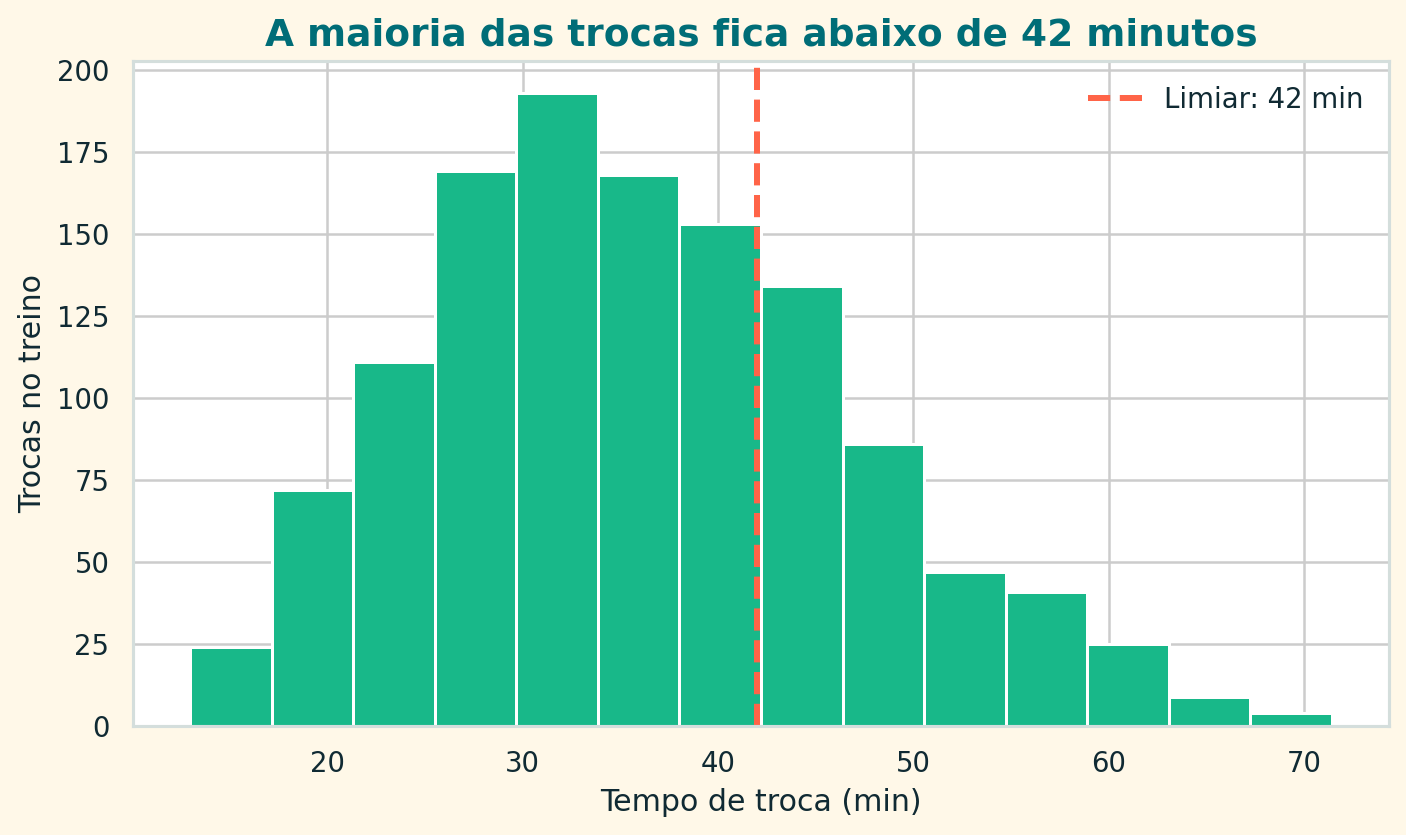

In [7]:
display(Image(filename="graficos/01_distribuicao_tempo.png", width=850))

A maioria das trocas fica abaixo do limite, mas a classe demorada ainda representa cerca de um quarto da base. A mediana é mais adequada que a média para preencher entradas porque é menos sensível aos valores extremos documentados.

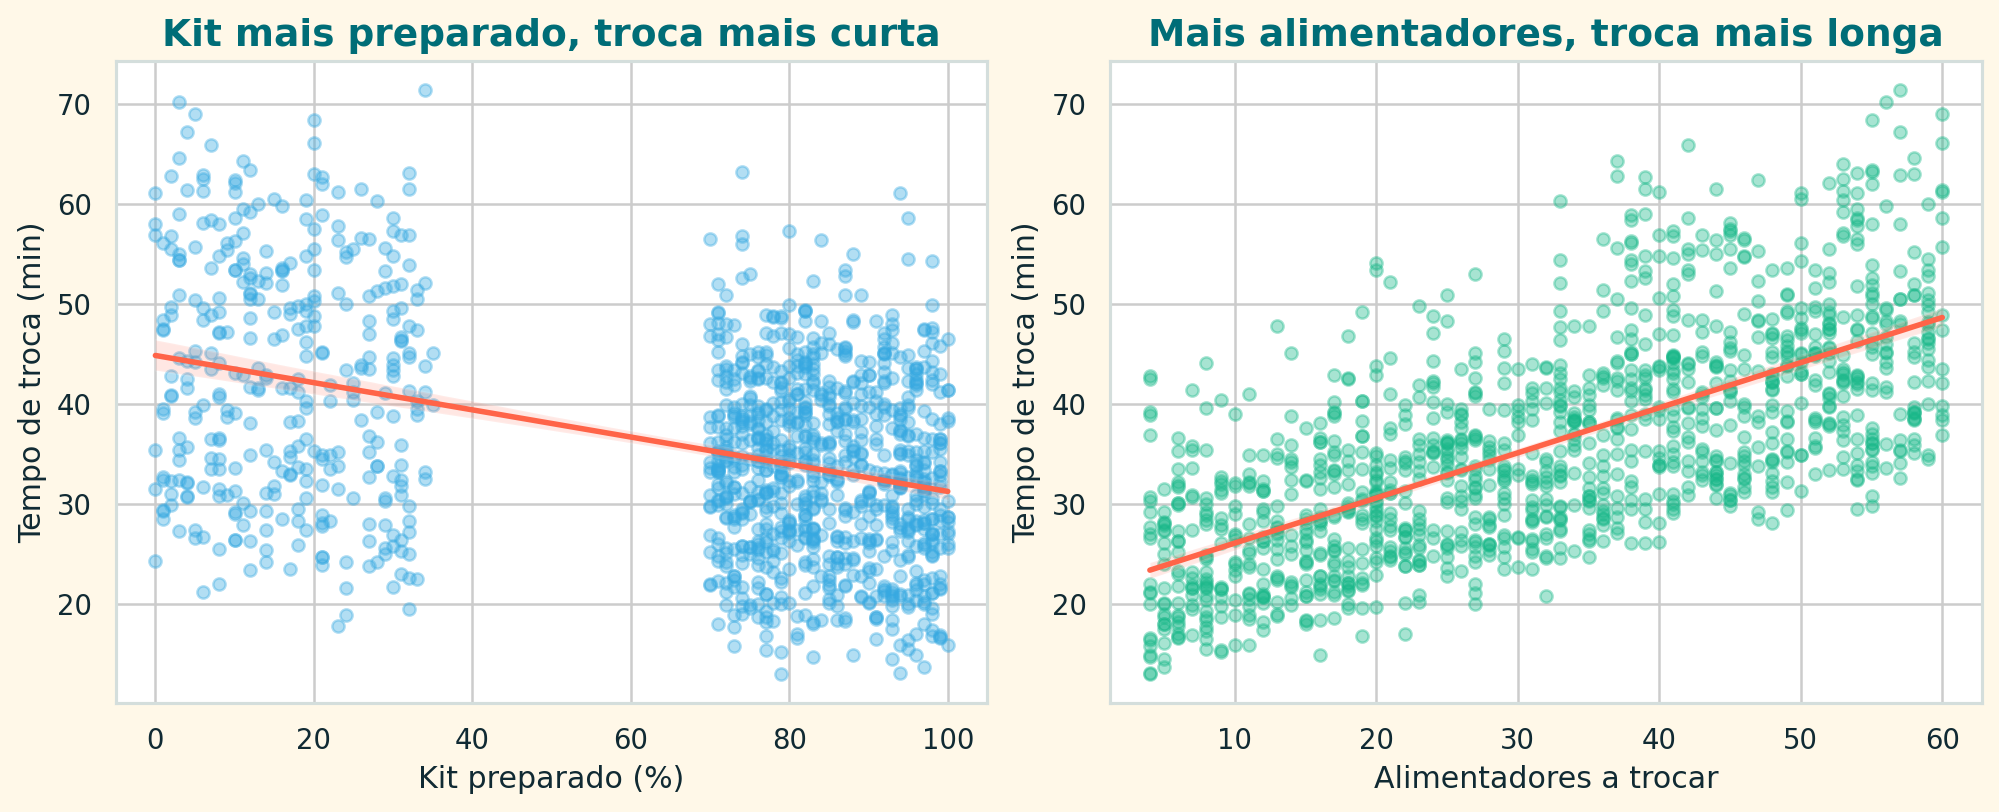

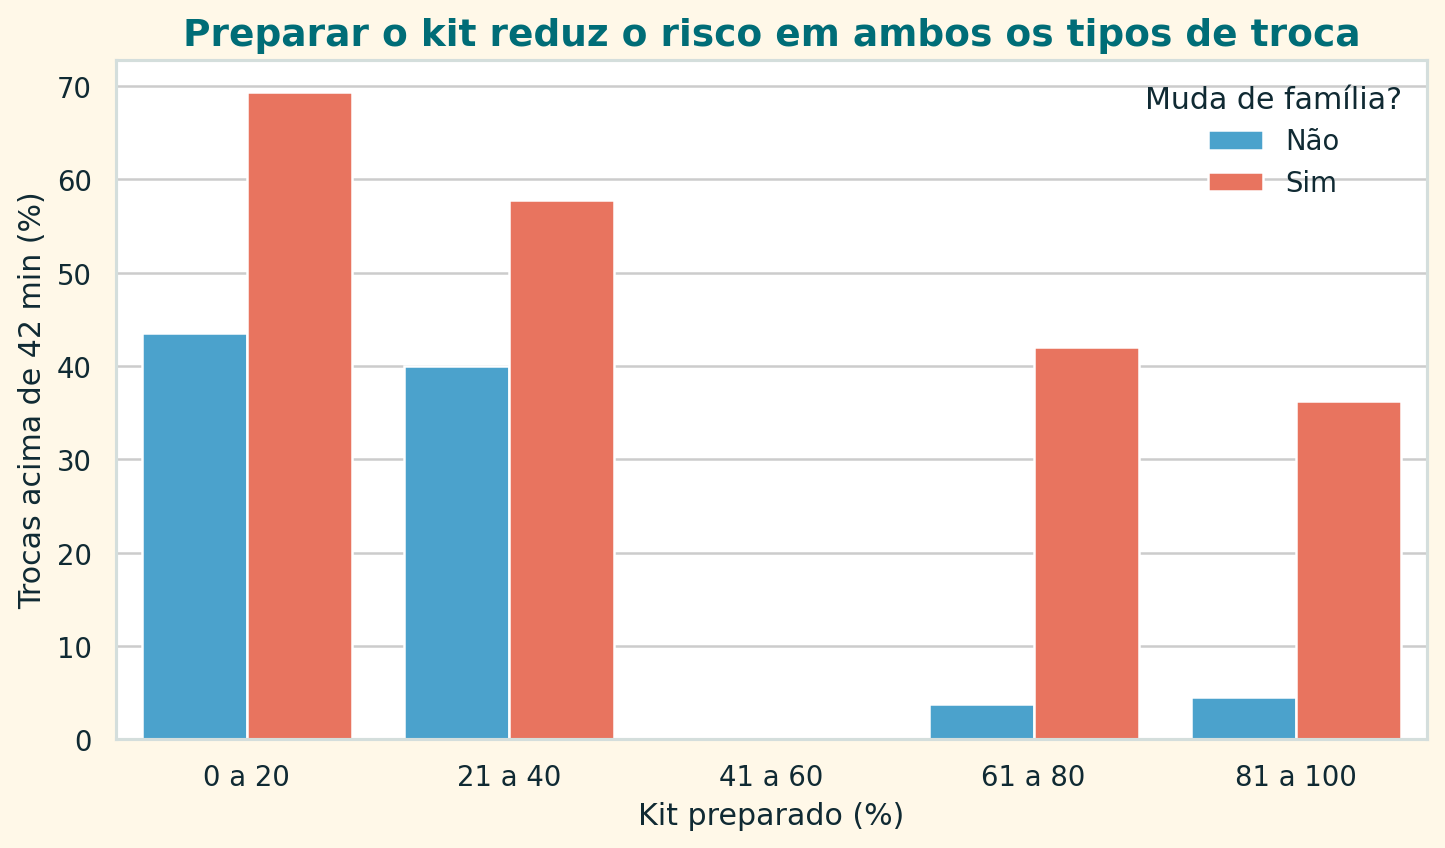

In [8]:
display(Image(filename="graficos/02_relacoes_principais.png", width=980))
display(Image(filename="graficos/03_risco_por_kit_e_familia.png", width=900))

### Leitura exploratória

- Maior preparação do kit aparece associada a tempos menores.
- Mais alimentadores a trocar aparece associado a tempos maiores.
- Mudar de família eleva o risco principalmente quando o kit está pouco preparado.

Essas relações orientam a interpretação, mas não provam causalidade.

## 6. Preparo e prevenção de vazamento

O pipeline aplica a mesma regra a todos os modelos:

- mediana para entradas numéricas ausentes;
- codificação `one-hot` para categorias;
- regras aprendidas apenas na parcela usada para treinar;
- exclusão de ID, datas, alvos e `atraso_no_plano_min`.

A coluna posterior ao evento foi preservada no arquivo limpo para rastreabilidade, mas nunca participa da previsão.

In [9]:
print("Entradas do modelo:")
for coluna in FEATURES:
    print("-", coluna)
print("\nFora das entradas: id, datas, alvos e atraso_no_plano_min")

Entradas do modelo:
- alimentadores_a_trocar
- kit_preparado_pct
- experiencia_operador_meses
- componentes_novos
- tamanho_lote_placas
- linha_smt
- muda_familia
- turno

Fora das entradas: id, datas, alvos e atraso_no_plano_min


## 7. Regressão: prever quantos minutos

Comparamos três ideias: a mediana do treino como referência, uma regressão linear e árvores com profundidades de 2 a 10. A profundidade é escolhida pelo menor MAE na validação. Depois, o modelo escolhido é treinado novamente com treino e validação e avaliado uma vez no teste.

In [10]:
resultados = train_and_evaluate(dados, divisao)

print("Melhores resultados de validação:")
display(resultados["regression_validation"].head(6).round(3))
print("Resultado final no teste:")
display(resultados["regression_test"].round(3))

Melhores resultados de validação:


,Modelo,MAE,RMSE,R2
7,Árvore prof. 7,2.699,3.490,0.897
8,Árvore prof. 8,2.760,3.548,0.893
6,Árvore prof. 6,2.771,3.525,0.895
10,Árvore prof. 10,2.808,3.609,0.890
9,Árvore prof. 9,2.813,3.609,0.890
5,Árvore prof. 5,2.977,3.795,0.878


Resultado final no teste:


,Modelo,MAE,RMSE,R2
2,Árvore prof. 7,2.656,3.501,0.884
1,Regressão linear,3.027,3.981,0.850
0,Referência mediana,8.137,10.310,-0.008


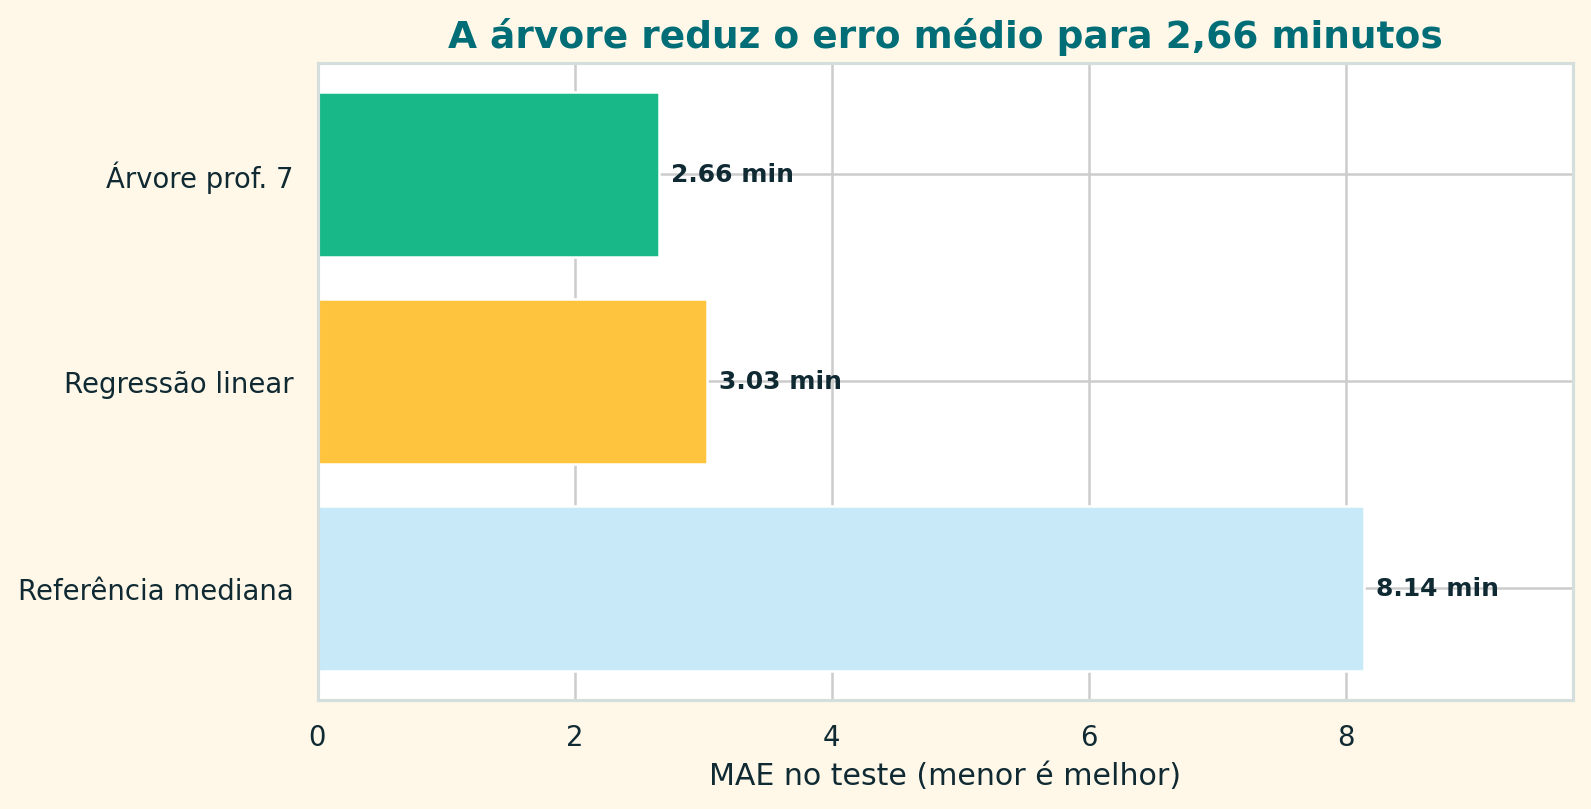

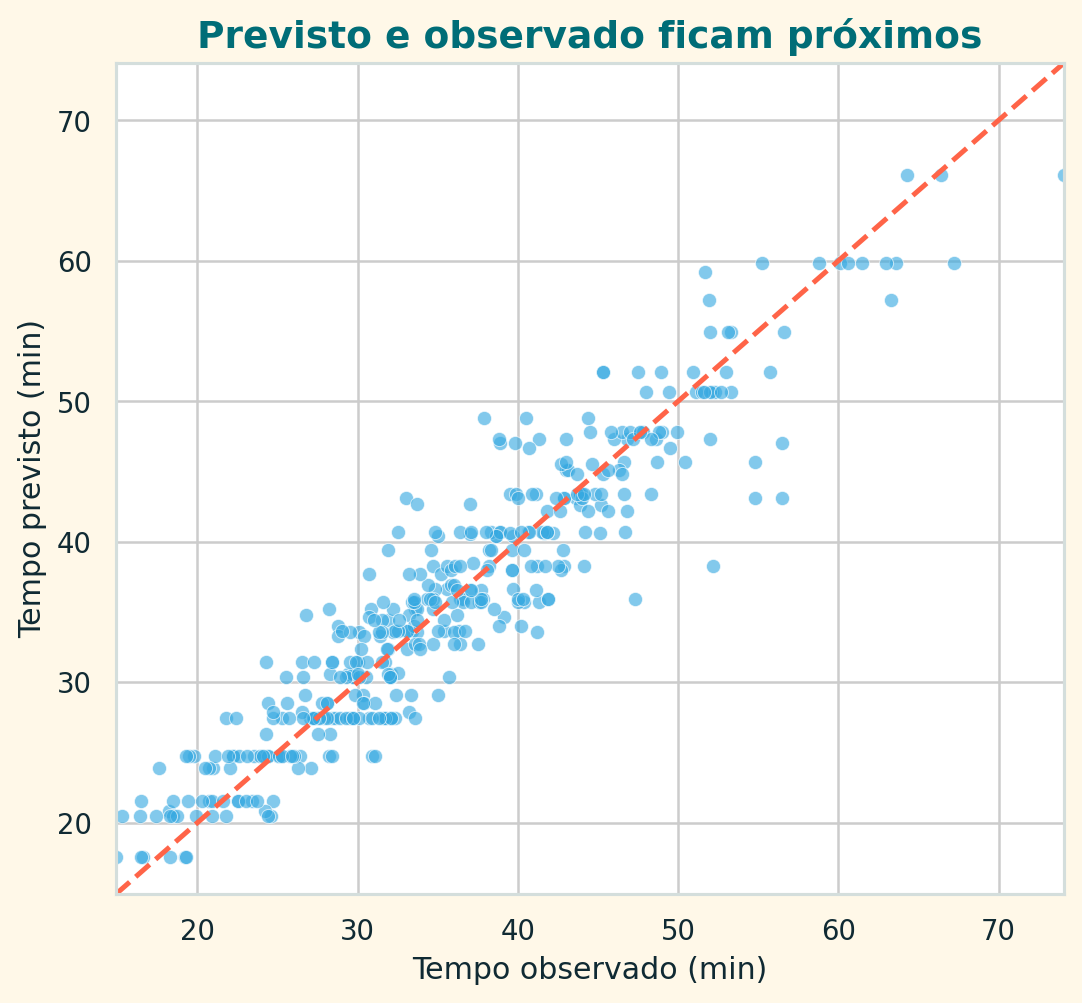

In [11]:
display(Image(filename="graficos/04_comparacao_regressao.png", width=850))
display(Image(filename="graficos/05_previsto_vs_observado.png", width=620))

### Resultado da regressão

A árvore de profundidade 7 alcançou MAE de **2,66 minutos** no teste. A referência simples errou **8,14 minutos** em média. A redução do erro foi de **67,4%**, com R² de **0,884**.

O ganho mostra que as entradas conhecidas antes da troca carregam informação útil. O erro não desaparece, então a previsão deve apoiar o supervisor e não substituir sua avaliação.

## 8. Classificação: prever risco acima de 42 minutos

A referência prevê sempre a classe mais comum. Também comparamos regressão logística e árvores de profundidade 2 a 10. Como perder uma troca demorada pode deixar a linha sem apoio, observamos `recall`, mas escolhemos a árvore pelo melhor F1 na validação para equilibrar casos encontrados e falsos alarmes.

In [12]:
colunas = ["Modelo", "Acurácia", "Precisão", "Recall", "F1", "AP", "FP", "FN", "VP"]
print("Melhores resultados de validação:")
display(resultados["classification_validation"][colunas].head(6).round(3))
print("Resultado final no teste:")
display(resultados["classification_test"][colunas].round(3))

Melhores resultados de validação:


,Modelo,Acurácia,Precisão,Recall,F1,AP,FP,FN,VP
4,Árvore prof. 4,0.936,0.822,0.951,0.882,0.917,21,5,97
5,Árvore prof. 5,0.933,0.800,0.980,0.881,0.932,25,2,100
6,Árvore prof. 6,0.931,0.803,0.961,0.875,0.901,24,4,98
3,Árvore prof. 3,0.933,0.832,0.922,0.874,0.876,19,8,94
7,Árvore prof. 7,0.908,0.748,0.961,0.841,0.891,33,4,98
8,Árvore prof. 8,0.908,0.748,0.961,0.841,0.891,33,4,98


Resultado final no teste:


,Modelo,Acurácia,Precisão,Recall,F1,AP,FP,FN,VP
2,Árvore prof. 4,0.891,0.742,0.873,0.802,0.880,31,13,89
1,Regressão logística,0.861,0.662,0.922,0.770,0.913,48,8,94
0,Referência maioria,0.747,0.000,0.000,0.000,0.253,0,102,0


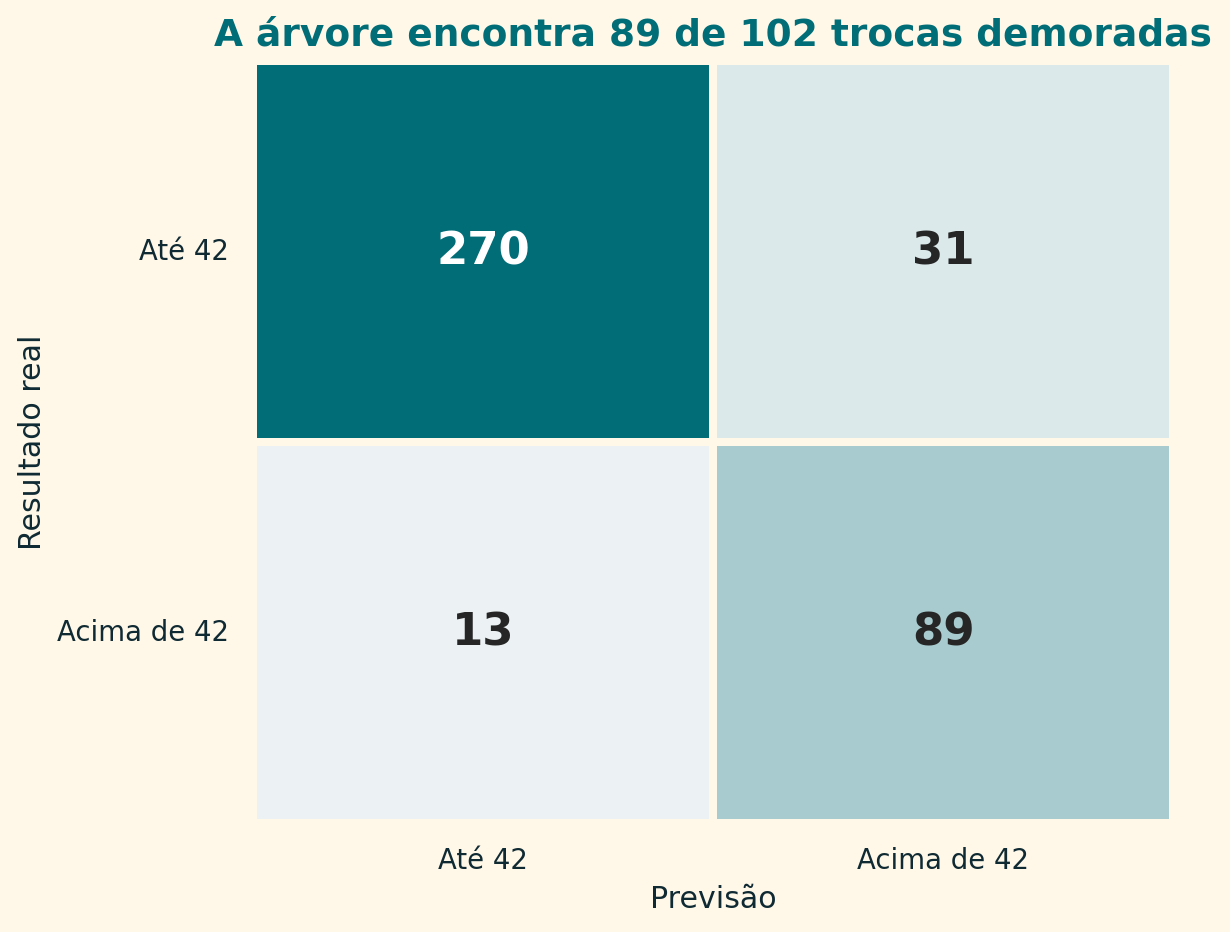

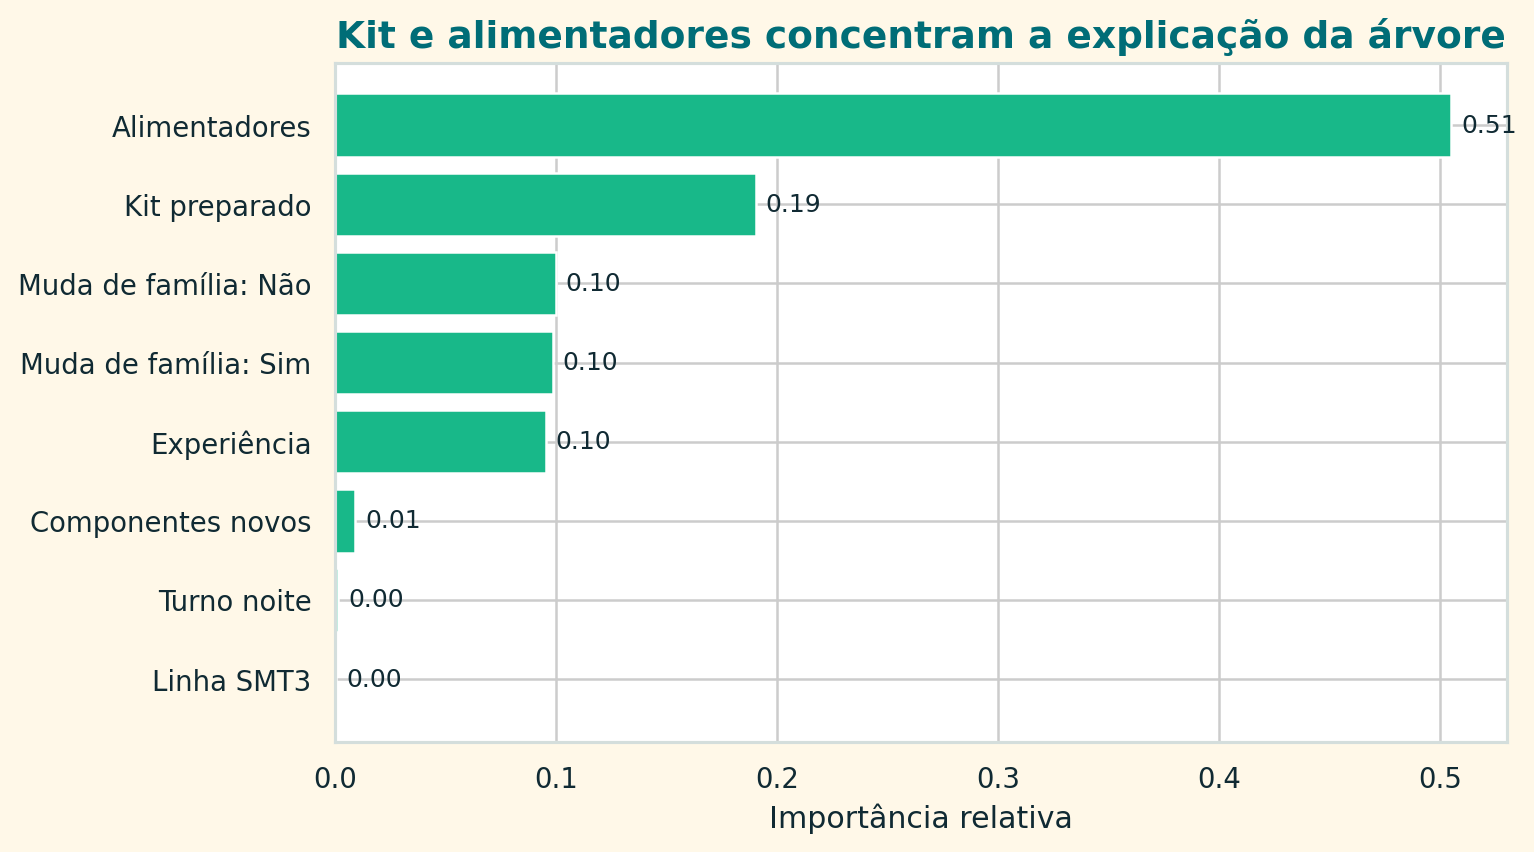

In [13]:
display(Image(filename="graficos/06_matriz_confusao.png", width=620))
display(Image(filename="graficos/07_importancia_caracteristicas.png", width=760))

### Resultado da classificação

No teste, a árvore de profundidade 4:

- encontrou **89 de 102** trocas demoradas;
- deixou passar **13** trocas demoradas;
- gerou **31** falsos alarmes;
- alcançou `recall` de **87,3%**, precisão de **74,2%** e F1 de **80,2%**.

A referência da classe majoritária não encontrou nenhuma troca demorada. O classificador, portanto, oferece um sinal operacional útil.

## 9. Como usar a previsão

Antes de cada troca, o sistema pode ordenar os casos pela probabilidade de ultrapassar 42 minutos. O supervisor direciona primeiro o apoio disponível para os maiores riscos e mantém sua decisão humana.

Uma política inicial pode usar o limite padrão de 50% e acompanhar três números por período:

1. trocas demoradas encontradas;
2. trocas demoradas perdidas;
3. falsos alarmes que consumiram atenção.

Se a prioridade for perder menos casos, o limite pode ser reduzido, aceitando mais falsos alarmes.

## 10. Limitações e aprendizados

- A base é sintética e não demonstra desempenho numa fábrica real.
- Associação entre kit preparado e duração não prova causa.
- Mudanças no processo, equipe ou produto podem reduzir o desempenho ao longo do tempo.
- O resultado precisa ser validado em operação antes de orientar recursos reais.
- Separar por tempo produz uma avaliação mais próxima do uso futuro.
- Uma referência simples é indispensável para saber se o modelo acrescenta valor.
- Vazamento de dados pode criar um resultado excelente e inútil.

## 11. Salvar resultados

A célula final atualiza a base limpa, auditorias, previsões de teste, métricas e gráficos usados na apresentação e no relatório.

In [14]:
generate_charts(dados, divisao, resultados, qualidade)
resumo = save_outputs(
    dados,
    divisao,
    fim_treino,
    fim_validacao,
    registro_limpeza,
    suspeitas,
    qualidade,
    resultados,
)
display(pd.Series(resumo, name="Resultado"))
print("Entregáveis analíticos atualizados.")

project                                                          SMT em Tempo
raw_rows                                                                 2057
clean_rows                                                               2043
exact_duplicates_removed                                                   14
date_start                                                         2026-01-05
date_end                                                           2026-08-28
train_end                                                          2026-05-27
validation_end                                                     2026-07-15
splits                      {'teste': {'records': 403, 'start': '2026-07-1...
delayed_rate                                                            0.272
target_median                                                            34.7
target_mean                                                            35.901
best_regression                                                Á

Entregáveis analíticos atualizados.


## 12. Respostas finais às perguntas do projeto

A análise partiu de 2.057 registros e preservou 2.043 após a remoção de 14 duplicatas exatas. Na base limpa, o tempo médio foi de **35,90 minutos**, a mediana foi de **34,70 minutos** e **27,2%** das trocas ultrapassaram 42 minutos.

### 1. Quantos minutos a troca deve levar?

Não existe um único tempo correto para todas as trocas. A resposta é a previsão individual produzida pela árvore de regressão a partir das oito informações conhecidas antes de a linha parar.

Nos **403 registros de teste**, a árvore de profundidade 7 apresentou:

- **MAE de 2,66 minutos**, ou seja, diferença absoluta média de 2,66 minutos entre o tempo previsto e o observado;
- **R² de 0,884**, indicando que o modelo explica 88,4% da variação observada nesse período;
- redução de **67,4% no erro** em comparação com a referência pela mediana, cujo MAE foi de 8,14 minutos.

Portanto, para uma nova troca, a coluna `tempo_previsto_min` é a resposta estimada. O MAE resume o erro médio observado no teste e não deve ser interpretado como margem garantida para cada caso.

### 2. A troca deve ultrapassar 42 minutos?

A árvore de classificação responde **Sim** quando identifica risco acima do limite operacional e **Não** nos demais casos. Entre as **102 trocas realmente demoradas** no teste:

- **89** foram identificadas corretamente;
- **13** não foram detectadas;
- **31** trocas abaixo do limite geraram falso alarme;
- o `recall` foi de **87,3%**, a precisão de **74,2%** e o F1 de **80,2%**.

Assim, o modelo encontra a maior parte das trocas demoradas e pode orientar a priorização do apoio. Ele não substitui a decisão do supervisor, pois ainda existem casos perdidos e falsos alarmes.

### Conclusão operacional

Os resultados respondem positivamente à pergunta central do projeto: os dados disponíveis antes da troca contêm informação suficiente para estimar a duração e antecipar o risco. A aplicação recomendada é ordenar as próximas trocas pela probabilidade de atraso, consultar o tempo estimado e direcionar primeiro o apoio humano para os maiores riscos.

Como a base é sintética, a decisão de uso real depende de uma validação com dados observados na fábrica e de acompanhamento contínuo dos erros.

In [15]:
respostas_finais = pd.DataFrame(
    [
        {
            "Pergunta": "Quantos minutos a troca deve levar?",
            "Resposta baseada no teste": (
                f"Mediana observada de {resumo['target_median']:.1f} min; "
                f"previsão individual com MAE de {resumo['test_mae']:.2f} min "
                f"e R² de {resumo['test_r2']:.3f}."
            ),
        },
        {
            "Pergunta": "A troca deve ultrapassar 42 minutos?",
            "Resposta baseada no teste": (
                f"Na base, {100 * resumo['delayed_rate']:.1f}% ultrapassaram o limite. "
                f"O modelo encontrou {resumo['true_positive']} das "
                f"{resumo['true_positive'] + resumo['false_negative']} trocas demoradas, "
                f"com recall de {100 * resumo['test_recall']:.1f}%."
            ),
        },
    ]
)
display(
    respostas_finais.style.hide(axis="index").set_properties(
        **{"white-space": "normal", "text-align": "left"}
    )
)

Pergunta,Resposta baseada no teste
Quantos minutos a troca deve levar?,Mediana observada de 34.7 min; previsão individual com MAE de 2.66 min e R² de 0.884.
A troca deve ultrapassar 42 minutos?,"Na base, 27.2% ultrapassaram o limite. O modelo encontrou 89 das 102 trocas demoradas, com recall de 87.3%."
